<a href="https://colab.research.google.com/github/ortizo-117/BMEG_591Q_group_project/blob/master/MLiM_Notebook1_COVID_LeNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML in Medicine — Workshop 2 Notebook 1 (PyTorch)
## COVID vs Normal chest X‑ray classification with a LeNet‑style CNN

**Folder structure expected (ImageFolder style):**
```
data/
  train/
    covid/
      *.png
    normal/
      *.png
  val/
    covid/
      *.png
    normal/
      *.png
```

This notebook trains a small **LeNet‑style CNN** (fast, from scratch) and includes:
- a clean training loop
- evaluation + confusion matrix + sensitivity/specificity
- visualization of a few misclassified images


In [ ]:

# Cell 1 — Imports and setup
import os
import math
import random
from typing import Dict, Tuple

import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
from torchvision import transforms
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt

# Reproducibility settings (helps students get similar results)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cpu')

## Point this notebook to your dataset

**Task:** Set `DATA_DIR` to the folder that contains `train/` and `val/`.




In [ ]:

# set path to da
# Cell 2 — Dataset path (EDIT THIS)

from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/data"  #  change me

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "val")

assert os.path.isdir(TRAIN_DIR), f"Train directory not found: {TRAIN_DIR}"
assert os.path.isdir(VAL_DIR), f"Val directory not found: {VAL_DIR}"

print("Train dir:", TRAIN_DIR)
print("Val dir:", VAL_DIR)


Mounted at /content/drive
Train dir: /content/drive/MyDrive/data/train
Val dir: /content/drive/MyDrive/data/val


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Transforms: grayscale, resize, normalize

Chest X‑rays are grayscale, but PNGs might be stored as 1‑channel or 3‑channel.
We explicitly convert to **1 channel** and resize to **64×64** so a LeNet‑style CNN trains quickly.

🔎 **Question:** What do we lose by resizing to 64×64? When would higher resolution matter?


In [ ]:

# Cell 3 — Transforms
# We use small 64x64 images so training is fast in a classroom setting.
# For stronger performance later, students can try 128x128 or 224x224.
IMG_SIZE = 64

train_tfms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),           # ensure 1 channel
    transforms.Resize((IMG_SIZE, IMG_SIZE)),               # make all images same size
    transforms.RandomHorizontalFlip(p=0.5),                # mild augmentation
    transforms.RandomRotation(degrees=7),                  # mild augmentation
    transforms.ToTensor(),                                 # converts to [0,1], shape (C,H,W)
    transforms.Normalize(mean=(0.5,), std=(0.5,)),         # scale to roughly [-1,1]
])

val_tfms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,)),
])


In [ ]:

# Cell 4 — Datasets and loaders
train_ds = ImageFolder(TRAIN_DIR, transform=train_tfms)
val_ds   = ImageFolder(VAL_DIR,   transform=val_tfms)

# ImageFolder maps class names to numeric labels (alphabetical by folder name)
print("Class-to-index mapping:", train_ds.class_to_idx)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print("Batch x shape:", xb.shape, "Batch y shape:", yb.shape)


Class-to-index mapping: {'covid': 0, 'normal': 1}
Batch x shape: torch.Size([64, 1, 64, 64]) Batch y shape: torch.Size([64])


## Quick data inspection

**Task:** Visualize a small grid of samples and verify labels look correct.

**Questions:**
1) Are the lungs centered similarly across images (or do you see shifts / rotations)?
2) Do COVID images show consistent patterns, or are they subtle?


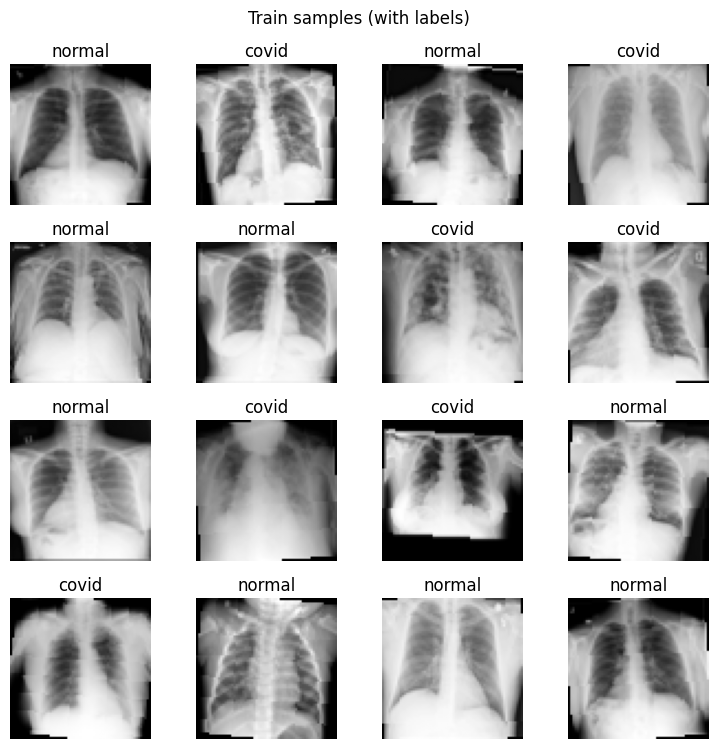

In [ ]:

# Cell 5 — Visualization helpers
def denorm(x: torch.Tensor) -> torch.Tensor:
    # Undo Normalize(mean=0.5, std=0.5) for display: x_display = x*0.5 + 0.5
    return x * 0.5 + 0.5

def show_grid(batch_x, batch_y, class_names, n=16, title="Samples"):
    n = min(n, batch_x.size(0), n)
    cols = int(math.sqrt(n))
    rows = int(math.ceil(n / cols))
    plt.figure(figsize=(1.9*cols, 1.9*rows))
    for i in range(n):
        plt.subplot(rows, cols, i+1)
        img = denorm(batch_x[i]).squeeze(0).cpu().numpy()
        plt.imshow(img, cmap="gray")
        plt.title(class_names[int(batch_y[i])])
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

class_names = train_ds.classes
show_grid(xb, yb, class_names, n=16, title="Train samples (with labels)")


## Model: LeNet‑style CNN (fast, from scratch)

This is inspired by LeNet:
- **Conv → ReLU → Pool** (twice)
- fully connected classifier

**Task:** Later you will modify the model to add **Dropout** and compare overfitting.


In [ ]:

# Cell 6 — LeNet-style CNN
class LeNetLike(nn.Module):
    # A compact CNN for 64x64 grayscale images.
    # It is intentionally small so it trains quickly in-class.
    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=5, padding=2),  # 64x64 -> 64x64
            nn.ReLU(),
            nn.MaxPool2d(2),                            # 64 -> 32

            nn.Conv2d(8, 16, kernel_size=5, padding=0), # 32 -> 28
            nn.ReLU(),
            nn.MaxPool2d(2),                            # 28 -> 14
        )

        # Compute flatten dimension dynamically (robust to IMG_SIZE changes)
        with torch.no_grad():
            dummy = torch.zeros(1, 1, IMG_SIZE, IMG_SIZE)
            out = self.features(dummy)
            flat_dim = out.view(1, -1).shape[1]

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, 128),
            nn.ReLU(),
            # Task later: insert nn.Dropout(p=0.3) here
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = LeNetLike(num_classes=len(class_names)).to(device)
model


LeNetLike(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [ ]:
# This is an extensively commented version of the cell above.
# =========================
# Cell 6 — LeNet-style CNN
# =========================
# This is NOT the historical "exact LeNet-5" from LeCun 1998.
# It is a small *LeNet-inspired* CNN that trains fast in-class on 64×64 grayscale images.
# Key modernizations vs. original LeNet-5:
#   - ReLU instead of tanh/sigmoid
#   - MaxPool instead of AvgPool (subsampling)
#   - Different channel counts (8,16 instead of 6,16)
#   - Uses padding in the first conv so spatial size stays constant

import torch
import torch.nn as nn

class LeNetLike(nn.Module):
    """
    A compact CNN for 64×64 grayscale images.

    Input:  (B, 1, 64, 64)
    Output: (B, num_classes)  # raw logits (NOT probabilities)
    B = batch size
    We split the network into:
      1) self.features: conv + activation + pooling (learns spatial features)
      2) self.classifier: flatten + fully connected layers (does classification)

    We also compute the flatten dimension dynamically, so you don't have to
    manually calculate the size that enters the first Linear layer.
    """

    def __init__(self, num_classes: int = 2, img_size: int = 64):
        """
        Args:
            num_classes: number of output classes (2 for covid vs normal)
            img_size: expected input spatial size (default 64)
        """
        super().__init__()

        # Store img_size (used for the dummy-forward shape computation below)
        self.img_size = img_size

        # ---------------------------
        # Feature extractor (CNN part)
        # ---------------------------
        # Shape math reminder (for each conv layer):
        #   out = floor((N + 2P - K)/S) + 1
        #
        # We'll assume stride S=1 for Conv2d and stride=2 for MaxPool2d(2).

        self.features = nn.Sequential(
            # Conv layer 1:
            #   in_channels=1  (grayscale)
            #   out_channels=8 (we learn 8 different filters)
            #   kernel_size=5  (each filter is 5×5)
            #   padding=2      (zero-pad 2 pixels on each side)
            #
            # Why padding=2?
            #   With kernel=5 and stride=1, padding=2 keeps the spatial size the same:
            #   64 -> 64 because (64 + 2*2 - 5)/1 + 1 = 64
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=5, padding=2),  # 64×64 -> 64×64
            nn.ReLU(),  # Nonlinearity: lets the network model complex functions

            # Max pooling:
            #   kernel_size=2, stride defaults to 2
            #   This halves H and W: 64 -> 32
            #   Pooling gives some translation invariance + reduces compute.
            nn.MaxPool2d(kernel_size=2),  # 64 -> 32

            # Conv layer 2:
            #   in_channels=8  (from previous layer's 8 feature maps)
            #   out_channels=16
            #   kernel_size=5
            #   padding=0  ("valid" conv, no padding)
            #
            # Spatial size shrinks: 32 -> 28 because (32 + 0 - 5)/1 + 1 = 28
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=5, padding=0),  # 32 -> 28
            nn.ReLU(),

            # Second pooling: 28 -> 14
            nn.MaxPool2d(kernel_size=2),  # 28 -> 14
        )

        # --------------------------------------------------------------------
        # Compute the flatten dimension automatically (robust to img_size changes)
        # --------------------------------------------------------------------
        # Why do this?
        #   The number of units entering the first Linear layer depends on:
        #     - input size (img_size)
        #     - conv kernel sizes/padding/stride
        #     - pooling
        #
        # Hard-coding is brittle:
        #   If you change img_size or layers, you'd have to re-do the math.
        #
        # So we do a "dummy forward pass" through self.features to discover
        # the output shape and compute the correct flatten size programmatically.

        with torch.no_grad():
            # Create a fake batch of 1 image with correct shape (B=1, C=1, H=img_size, W=img_size)
            dummy = torch.zeros(1, 1, self.img_size, self.img_size)

            # Pass it through the conv/pool stack to see what comes out
            out = self.features(dummy)

            # Flatten everything except the batch dimension:
            #   out is (1, C, H, W)  -> view(1, -1) is (1, C*H*W)
            # shape[1] gives C*H*W, the number of inputs to the first Linear layer.
            flat_dim = out.view(1, -1).shape[1]

        # ---------------------------
        # Classifier (fully-connected)
        # ---------------------------
        # We output "logits" (unnormalized scores). We do NOT apply softmax here because:
        #   torch.nn.CrossEntropyLoss expects logits and applies log-softmax internally.

        self.classifier = nn.Sequential(
            nn.Flatten(),                  # (B, 16, 14, 14) -> (B, flat_dim)
            nn.Linear(flat_dim, 128),      # dense layer to learn a compact representation
            nn.ReLU(),

            # Student task (later):
            # Insert dropout here to reduce overfitting, e.g.
            # nn.Dropout(p=0.3),

            nn.Linear(128, num_classes),   # final layer: produces logits for each class
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass.

        Args:
            x: input tensor of shape (B, 1, img_size, img_size)

        Returns:
            logits: tensor of shape (B, num_classes)
        """
        x = self.features(x)     # conv/pool feature extraction
        x = self.classifier(x)   # flatten + MLP classification head
        return x

# Instantiate the model:
# - num_classes should match your dataset (e.g., 2: covid vs normal)
# - move to device (CPU/GPU)
model_LeNetLike = LeNetLike(num_classes=len(class_names), img_size=IMG_SIZE).to(device)
model_LeNetLike

LeNetLike(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)

## Task: Implement the original LeNet-5 (LeCun et al., 1998) and compare

So far, you have trained a **LeNet-style CNN** that is inspired by LeNet-5 but is **not identical** to the original architecture shown in the lecture.

In this task, you will implement the **canonical LeNet-5 architecture exactly as presented in the lecture slides**, and compare its behavior to the modernized version used above.

---

### Architecture requirements (must match the lecture diagram)

Implement a PyTorch model class called `LeNet5Exact` with the following structure:

**Input**
- Grayscale image of size **32 × 32 × 1**

**C1 – Convolution**
- `Conv2d(1 → 6)`
- Kernel size: **5 × 5**
- Padding: **0 (valid convolution)**
- Output: **28 × 28 × 6**
- Activation: `ReLU`

**S2 – Subsampling**
- **Average pooling**
- Kernel size: 2, stride: 2
- Output: **14 × 14 × 6**

**C3 – Convolution**
- `Conv2d(6 → 16)`
- Kernel size: **5 × 5**
- Padding: 0
- Output: **10 × 10 × 16**
- Activation: `ReLU`

**S4 – Subsampling**
- **Average pooling**
- Kernel size: 2, stride: 2
- Output: **5 × 5 × 16**

**Fully connected layers**
- Flatten → **400 units**
- `Linear(400 → 120)` + ReLU
- `Linear(120 → 84)` + ReLU
- `Linear(84 → num_classes)`

> **Note:**  
> The original LeNet-5 used `tanh` activations. We use `ReLU` here for consistency with modern training practice.

---

### Training protocol

- Resize all input images to **32 × 32**
- Use the **same optimizer, learning rate, batch size, and number of epochs** as the LeNet-style model above
- Do **not** add:
  - padding
  - batch normalization
  - dropout
  - extra layers

---

### Compare the two models

After training both models, compare:

- Training accuracy vs validation accuracy
- Speed of convergence
- Signs of overfitting
- Stability of training
- Types of errors (false positives vs false negatives)

---

### Answer the following questions

1. Why does the original LeNet-5 require **32 × 32** inputs?
2. How does **average pooling** differ from max pooling in terms of information retention?
3. Which model generalizes better on the chest X-ray dataset, and why?
4. Why might LeNet-5 work well for MNIST but struggle with medical images?
5. Which design choices in modern CNNs address these limitations?

---

###  Deliverable

- Your `LeNet5Exact` PyTorch implementation
- A short written comparison (≈½ page) addressing the questions above

## Training loop + evaluation

We use:
- **CrossEntropyLoss** (standard for multi-class classification; for 2 classes it still applies)
- **Adam** optimizer
- accuracy for quick feedback

**Question:** Why do we not apply `softmax` inside the model when using `CrossEntropyLoss`?


In [ ]:
import torch
import torch.nn as nn

class LeNet5Exact(nn.Module):
    """
    LeNet-5 style CNN.

    Spec (exact when img_size = 32):
      C1: Conv2d(1 -> 6, 5x5, padding=0) + ReLU      => 28x28x6
      S2: AvgPool2d(2,2)                              => 14x14x6
      C3: Conv2d(6 -> 16, 5x5, padding=0) + ReLU     => 10x10x16
      S4: AvgPool2d(2,2)                              => 5x5x16
      Flatten => 400
      FC: 400->120->84->num_classes (ReLU between)

    If img_size is NOT 32 (e.g., 64), the conv/pool outputs won't be 5x5,
    so the flatten size won't be 400. This class will still work because we
    compute flat_dim dynamically.
    """

    def __init__(self, num_classes: int = 2, img_size: int = 64):
        super().__init__()
        self.img_size = img_size

        # ---------------------------
        # Feature extractor (CNN part)
        # ---------------------------
        self.features = nn.Sequential(
            # C1: valid conv (no padding)
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, padding=0),
            nn.ReLU(),

            # S2: average pooling (instead of max pooling)
            nn.AvgPool2d(kernel_size=2, stride=2),

            # C3: valid conv (no padding)
            nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, padding=0),
            nn.ReLU(),

            # S4: average pooling
            nn.AvgPool2d(kernel_size=2, stride=2),
        )

        # Dynamically compute flatten dimension (robust to img_size changes)
        with torch.no_grad():
            dummy = torch.zeros(1, 1, self.img_size, self.img_size)
            out = self.features(dummy)
            flat_dim = out.view(1, -1).shape[1]

        # ---------------------------
        # Classifier (fully-connected)
        # ---------------------------
        # If img_size == 32, flat_dim should be 16*5*5 = 400 (classic LeNet-5).
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.classifier(x)
        return x


# Instantiate the model
model_LeNet5Exact = LeNet5Exact(num_classes=len(class_names), img_size=IMG_SIZE).to(device)
print(model_LeNet5Exact)
model_LeNetLike


LeNet5Exact(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2704, out_features=120, bias=True)
    (2): ReLU()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): ReLU()
    (5): Linear(in_features=84, out_features=2, bias=True)
  )
)


LeNetLike(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [ ]:

# Cell 7 — Train/eval helpers
@torch.no_grad()
def evaluate(model, loader, criterion) -> Tuple[float, float]:
    # Returns (average_loss, accuracy)
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)                 # raw scores ("logits")
        loss = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)      # predicted class = argmax over logits
        total_correct += (preds == y).sum().item()
        total += x.size(0)

    return total_loss / total, total_correct / total

def train_model(model, train_loader, val_loader, epochs=8, lr=1e-3, weight_decay=1e-4):
    # CrossEntropyLoss expects raw logits (no softmax) and integer class labels
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, running_correct, total = 0.0, 0, 0

        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()              # compute gradients
            optimizer.step()             # update parameters

            running_loss += loss.item() * x.size(0)
            preds = logits.argmax(dim=1)
            running_correct += (preds == y).sum().item()
            total += x.size(0)

        train_loss = running_loss / total
        train_acc = running_correct / total
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch:02d}/{epochs} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.3f}")

    return history

def plot_curves(history: Dict[str, list]):
    plt.figure(figsize=(7,4))
    plt.plot(history["train_loss"], label="train_loss")
    plt.plot(history["val_loss"], label="val_loss")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Loss curves")
    plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(history["train_acc"], label="train_acc")
    plt.plot(history["val_acc"], label="val_acc")
    plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.title("Accuracy curves")
    plt.show()


In [ ]:
# This is a highly commented version of the cell above.
# ==============================
# Cell 7 — Train / Evaluation helpers
# ==============================
# This cell defines:
#   1) evaluate(): runs the model on a dataset WITHOUT training
#   2) train_model(): full training loop (train + validation per epoch)
#   3) plot_curves(): visualize loss and accuracy over epochs
#
# Key ideas illustrated here:
#   - Difference between model.train() and model.eval()
#   - Why we use torch.no_grad() during evaluation
#   - Why CrossEntropyLoss expects *raw logits*
#   - How accuracy is computed from logits

from typing import Tuple, Dict
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt


# --------------------------------------------------
# Evaluation function (NO gradient computation)
# --------------------------------------------------
@torch.no_grad()   # Disables gradient tracking inside this function
def evaluate(model, loader, criterion) -> Tuple[float, float]:
    """
    Evaluate a model on a dataset.

    Args:
        model: trained (or partially trained) neural network
        loader: DataLoader for validation or test set
        criterion: loss function (e.g., CrossEntropyLoss)

    Returns:
        average_loss: mean loss over all samples
        accuracy: fraction of correctly classified samples
    """

    # Put the model in evaluation mode:
    # - disables Dropout
    # - uses running statistics for BatchNorm (if present)
    model.eval()

    # Accumulators for loss and accuracy
    total_loss = 0.0
    total_correct = 0
    total = 0   # total number of samples seen

    # Loop over batches
    for x, y in loader:
        # Move data to CPU/GPU
        x = x.to(device)
        y = y.to(device)

        # Forward pass:
        # model(x) returns raw scores ("logits"), NOT probabilities
        logits = model(x)

        # Compute loss for this batch
        loss = criterion(logits, y)

        # Accumulate weighted loss:
        #   loss.item() is the *average* loss over the batch
        #   multiply by batch size to get total loss contribution
        total_loss += loss.item() * x.size(0)

        # Predicted class = index of largest logit
        preds = logits.argmax(dim=1)

        # Count how many predictions are correct
        total_correct += (preds == y).sum().item()

        # Count number of samples processed
        total += x.size(0)

    # Compute averages over the entire dataset
    average_loss = total_loss / total
    accuracy = total_correct / total

    return average_loss, accuracy


# --------------------------------------------------
# Training loop (with validation each epoch)
# --------------------------------------------------
def train_model(
    model,
    train_loader,
    val_loader,
    epochs: int = 8,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
):
    """
    Train a model and evaluate it on a validation set each epoch.

    Args:
        model: neural network to train
        train_loader: DataLoader for training data
        val_loader: DataLoader for validation data
        epochs: number of training epochs
        lr: learning rate
        weight_decay: L2 regularization strength

    Returns:
        history: dictionary containing loss/accuracy curves
    """

    # CrossEntropyLoss expects:
    #   - raw logits of shape (B, num_classes)
    #   - integer class labels of shape (B,)
    # IMPORTANT: Do NOT apply softmax before this loss.
    criterion = nn.CrossEntropyLoss()

    # Adam optimizer updates model parameters using gradients
    optimizer = optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    # Store training history for plotting later
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    # Epoch loop
    for epoch in range(1, epochs + 1):

        # Put model in training mode:
        # - enables Dropout
        # - BatchNorm (if any) updates running statistics
        model.train()

        running_loss = 0.0
        running_correct = 0
        total = 0

        # Loop over training batches
        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)

            # Clear gradients from previous step
            optimizer.zero_grad()

            # Forward pass
            logits = model(x)

            # Compute loss
            loss = criterion(logits, y)

            # Backpropagation:
            # compute gradients of loss w.r.t. parameters
            loss.backward()

            # Update model parameters
            optimizer.step()

            # Accumulate loss (weighted by batch size)
            running_loss += loss.item() * x.size(0)

            # Compute predictions
            preds = logits.argmax(dim=1)

            # Accumulate correct predictions
            running_correct += (preds == y).sum().item()

            # Accumulate sample count
            total += x.size(0)

        # Compute training metrics for this epoch
        train_loss = running_loss / total
        train_acc = running_correct / total

        # Evaluate on validation set (NO gradients)
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        # Store metrics
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Print progress
        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.3f}"
        )

    return history


# --------------------------------------------------
# Plot training curves
# --------------------------------------------------
def plot_curves(history: Dict[str, list]):
    """
    Plot loss and accuracy curves stored in the history dictionary.
    """

    # Loss curves
    plt.figure(figsize=(7, 4))
    plt.plot(history["train_loss"], label="train_loss")
    plt.plot(history["val_loss"], label="val_loss")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("Loss curves")
    plt.legend()
    plt.show()

    # Accuracy curves
    plt.figure(figsize=(7, 4))
    plt.plot(history["train_acc"], label="train_acc")
    plt.plot(history["val_acc"], label="val_acc")
    plt.xlabel("epoch")
    plt.ylabel("accuracy")
    plt.title("Accuracy curves")
    plt.legend()
    plt.show()

## Train the model

**Task:** Run training. Then try:
- `epochs=15`
- `lr=1e-4` vs `1e-3`
- `IMG_SIZE=128` (expect slower training)

🔎 **Question:** Do you see overfitting (train improving while val stagnates/drops)?


Epoch 01/8 | train_loss=0.6736 train_acc=0.582 | val_loss=0.6352 val_acc=0.677
Epoch 02/8 | train_loss=0.5997 train_acc=0.689 | val_loss=0.5715 val_acc=0.694
Epoch 03/8 | train_loss=0.5437 train_acc=0.705 | val_loss=0.5349 val_acc=0.702
Epoch 04/8 | train_loss=0.5188 train_acc=0.743 | val_loss=0.5165 val_acc=0.742
Epoch 05/8 | train_loss=0.4823 train_acc=0.766 | val_loss=0.4884 val_acc=0.754
Epoch 06/8 | train_loss=0.4601 train_acc=0.760 | val_loss=0.5308 val_acc=0.762
Epoch 07/8 | train_loss=0.4441 train_acc=0.777 | val_loss=0.4529 val_acc=0.778
Epoch 08/8 | train_loss=0.4049 train_acc=0.806 | val_loss=0.4412 val_acc=0.794


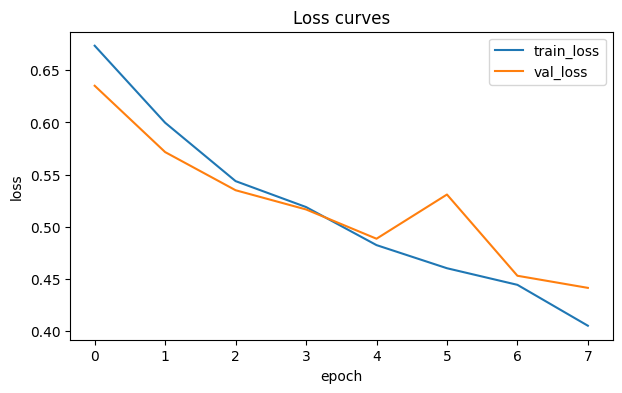

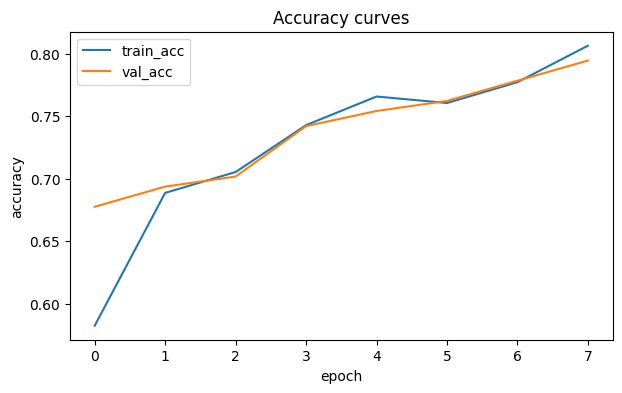

In [ ]:

# Cell 8 — Train
model = LeNetLike(num_classes=len(class_names)).to(device)
history = train_model(model, train_loader, val_loader, epochs=8, lr=1e-3, weight_decay=1e-4)
plot_curves(history)
# Weight decay is a form of regularization that discourages a neural network from learning overly large weights.

Epoch 01/8 | train_loss=0.4270 train_acc=0.816 | val_loss=2.2339 val_acc=0.500
Epoch 02/8 | train_loss=0.3401 train_acc=0.904 | val_loss=0.8909 val_acc=0.500
Epoch 03/8 | train_loss=0.3216 train_acc=0.904 | val_loss=1.2378 val_acc=0.500
Epoch 04/8 | train_loss=0.2984 train_acc=0.904 | val_loss=1.0283 val_acc=0.500
Epoch 05/8 | train_loss=0.2939 train_acc=0.904 | val_loss=1.1321 val_acc=0.500
Epoch 06/8 | train_loss=0.2885 train_acc=0.904 | val_loss=1.0456 val_acc=0.500
Epoch 07/8 | train_loss=0.2856 train_acc=0.904 | val_loss=1.0348 val_acc=0.500
Epoch 08/8 | train_loss=0.2847 train_acc=0.904 | val_loss=0.9897 val_acc=0.500


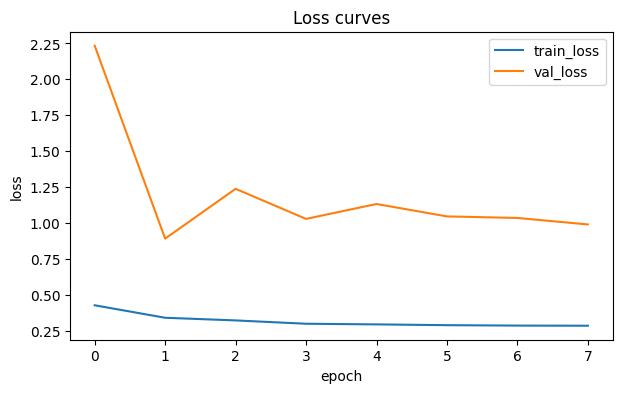

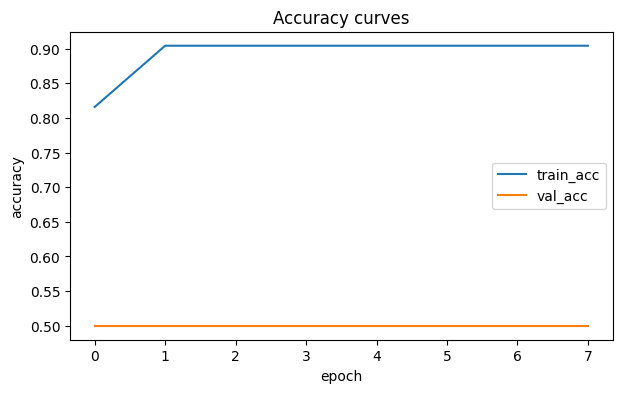

In [ ]:
# Cell 8 — Train
model = LeNet5Exact(num_classes=len(class_names)).to(device)
history = train_model(model, train_loader, val_loader, epochs=8, lr=1e-3, weight_decay=1e-4)
plot_curves(history)

## Confusion matrix + sensitivity/specificity

In medical screening tasks, accuracy alone can be misleading.

We treat **COVID** as the "positive" class. Depending on your folder naming,
`ImageFolder` assigns indices alphabetically.

**Task:** Confirm which numeric label corresponds to COVID by checking `train_ds.class_to_idx`.


In [ ]:

# Cell 9 — Confusion matrix and metrics (no sklearn)
@torch.no_grad()
def confusion_matrix(model, loader, num_classes=2) -> np.ndarray:
    # rows = true label, cols = predicted label
    model.eval()
    cm = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)
        preds = logits.argmax(dim=1)
        for t, p in zip(y.view(-1), preds.view(-1)):
            cm[t.long(), p.long()] += 1
    return cm.cpu().numpy()

def metrics_binary_from_cm(cm: np.ndarray, positive_label: int) -> Dict[str, float]:
    # Computes metrics where 'positive_label' is the positive class.
    assert cm.shape == (2, 2)

    if positive_label == 1:
        tn, fp = cm[0,0], cm[0,1]
        fn, tp = cm[1,0], cm[1,1]
    else:
        # swap roles: pos=0, neg=1
        tn, fp = cm[1,1], cm[1,0]
        fn, tp = cm[0,1], cm[0,0]

    acc = (tp + tn) / (tp + tn + fp + fn + 1e-12)
    precision = tp / (tp + fp + 1e-12)
    sensitivity = tp / (tp + fn + 1e-12)  # recall
    specificity = tn / (tn + fp + 1e-12)

    return {
        "accuracy": float(acc),
        "precision": float(precision),
        "sensitivity_recall": float(sensitivity),
        "specificity": float(specificity),
        "tp": float(tp), "tn": float(tn), "fp": float(fp), "fn": float(fn),
    }

cm = confusion_matrix(model, val_loader, num_classes=len(class_names))
print("Confusion matrix (rows=true, cols=pred):\n", cm)
print("Class names:", class_names)


Confusion matrix (rows=true, cols=pred):
 [[119   5]
 [ 57  67]]
Class names: ['covid', 'normal']




🔎 **Questions:**
1) If sensitivity is low, what kind of clinical risk does that imply?
2) If specificity is low, what kind of practical cost does that imply?


In [ ]:

# Cell 10 — Set the COVID label index
# Example mapping might be: {'covid': 0, 'normal': 1}
COVID_LABEL = train_ds.class_to_idx.get("covid", 0)  # verify this is correct!
metrics = metrics_binary_from_cm(cm, positive_label=COVID_LABEL)
metrics


{'accuracy': 0.749999999999997,
 'precision': 0.6761363636363598,
 'sensitivity_recall': 0.959677419354831,
 'specificity': 0.5403225806451569,
 'tp': 119.0,
 'tn': 67.0,
 'fp': 57.0,
 'fn': 5.0}

## Error analysis: visualize misclassified images

**Task:** Look at misclassified cases and hypothesize why.
Common issues in chest X‑ray datasets:
- different machines / post-processing (domain shift)
- text markers, borders, embedded annotations (spurious shortcuts)
- patient positioning differences


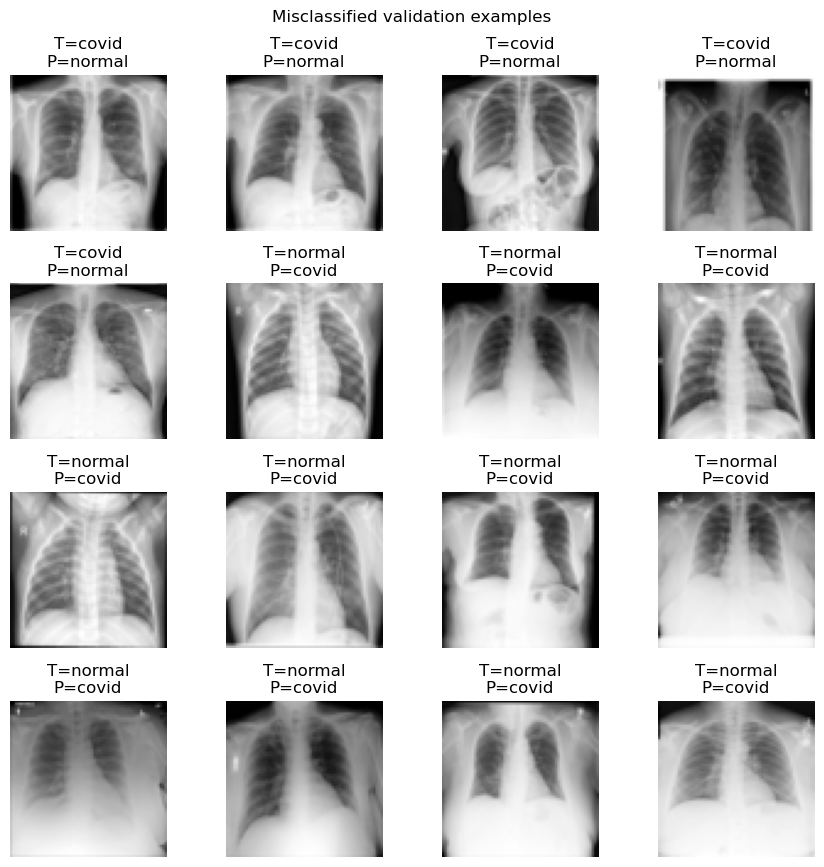

In [ ]:

# Cell 11 — Find and display misclassifications from validation set
@torch.no_grad()
def get_misclassified(model, loader, max_items=16):
    model.eval()
    bad = []
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)
        preds = logits.argmax(dim=1)
        wrong = preds != y
        if wrong.any():
            xw = x[wrong].cpu()
            yw = y[wrong].cpu()
            pw = preds[wrong].cpu()
            for i in range(len(yw)):
                bad.append((xw[i], int(yw[i]), int(pw[i])))
                if len(bad) >= max_items:
                    return bad
    return bad

def show_misclassified(bad_list, class_names, n=16, title="Misclassified"):
    n = min(n, len(bad_list))
    if n == 0:
        print("No misclassifications found (or max_items too small).")
        return
    cols = int(math.sqrt(n))
    rows = int(math.ceil(n / cols))
    plt.figure(figsize=(2.2*cols, 2.2*rows))
    for i in range(n):
        img, ytrue, ypred = bad_list[i]
        img_disp = denorm(img).squeeze(0).numpy()
        plt.subplot(rows, cols, i+1)
        plt.imshow(img_disp, cmap="gray")
        plt.title(f"T={class_names[ytrue]}\nP={class_names[ypred]}")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

bad = get_misclassified(model, val_loader, max_items=16)
show_misclassified(bad, class_names, n=16, title="Misclassified validation examples")


## Extensions (for next week)

**Task A (regularization):** Add `nn.Dropout(p=0.3)` into the classifier and compare curves.

**Task B (class imbalance):**
- Print class counts in train/val.
- If imbalanced, use a **weighted loss**:
  `nn.CrossEntropyLoss(weight=torch.tensor([...], device=device))`

**Task C (better model):**
- Replace LeNetLike with a pretrained model (e.g., ResNet18) and fine-tune.
  (This becomes Notebook 2: transfer learning.)

**Question:** Why might transfer learning work even though ImageNet is not medical?


In [ ]:

# Cell 12 — Class counts (useful for imbalance discussion)
def class_counts(dataset: ImageFolder):
    counts = {name: 0 for name in dataset.classes}
    for _, label in dataset.samples:
        counts[dataset.classes[label]] += 1
    return counts

print("Train counts:", class_counts(train_ds))
print("Val counts:  ", class_counts(val_ds))


Train counts: {'covid': 469, 'normal': 491}
Val counts:   {'covid': 124, 'normal': 124}
